In [1]:
root = "M://Diploma/experiments/vesuvius/fragments"

### Data overview

Downloaded file structure:
```
fragments/
    Frag1/
        inklabels.png
        ir.png
        mask.png
        surface_volume/
            00-64.tif
```
Let's look at those examples to understand, what we will be working with

d:\Programs\Programming\Python\lib\site-packages\PIL\Image.py:3402: DecompressionBombWarning: Image size (140973980 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


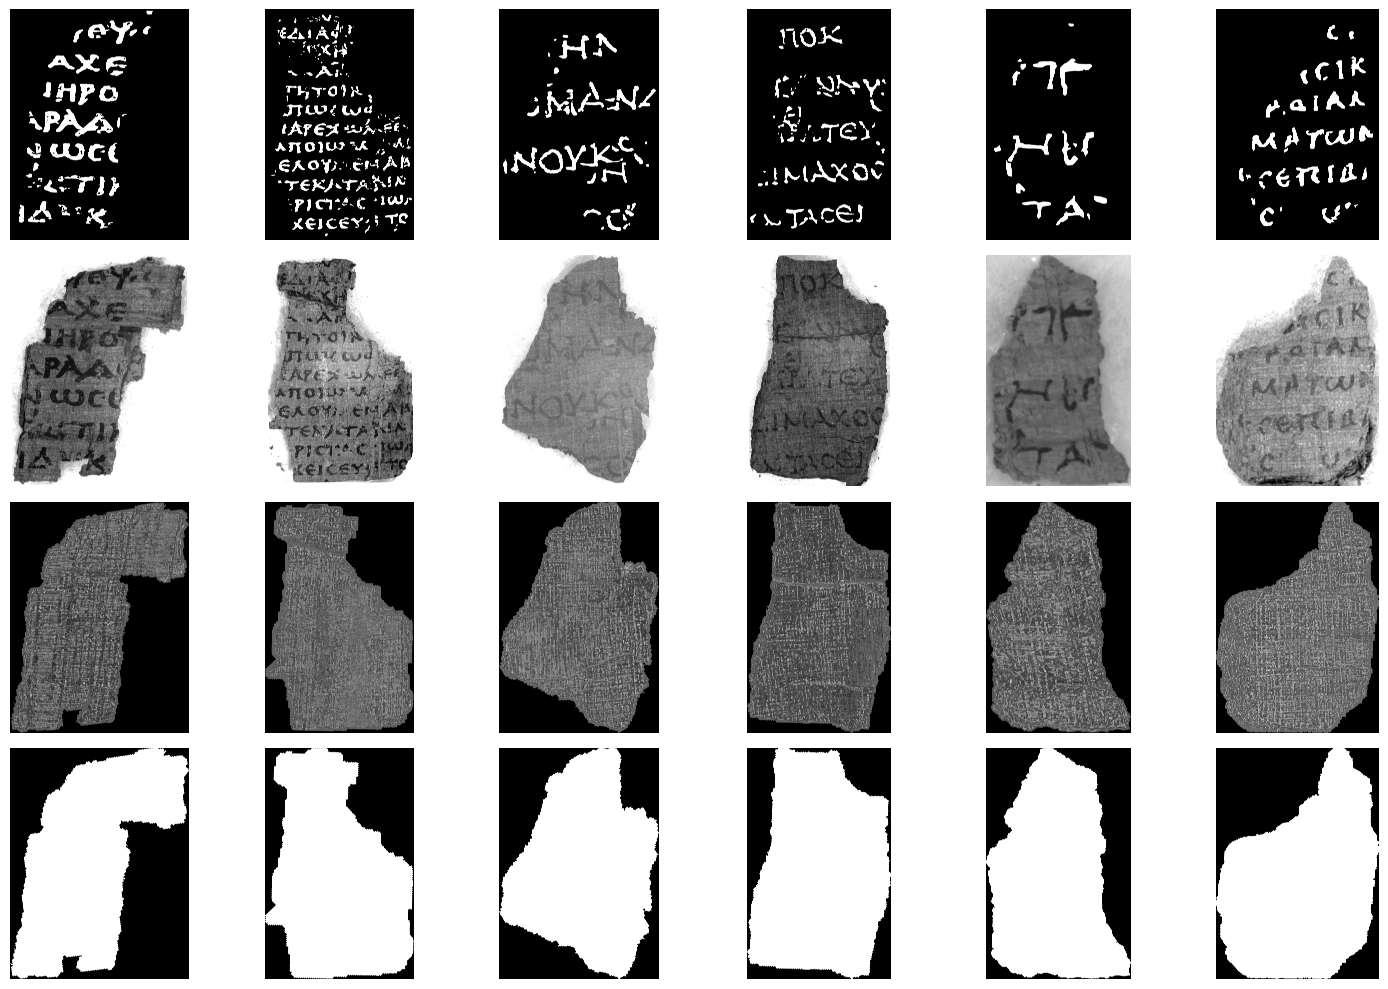

In [2]:
import PIL.Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 6, figsize=(15, 10))
for i in range(6):
    # This is the target variable - segmentation masks, which we will be trying to predict
    axes[0][i].imshow(PIL.Image.open(f"{root}/Frag{i + 1}/inklabels.png"), cmap='gray')

    # Infrared scan. Not part of the competition's objective,
    # but may be useful as an easier version of the problem.
    # Unlike CT, in IR the ink is easily recognizable
    axes[1][i].imshow(PIL.Image.open(f"{root}/Frag{i + 1}/ir.png"), cmap='gray')

    # And the actual CT scans, which are the primary target of the competition.
    # 65 images per fragment, showing consequitive layers of the rollout fragment.
    # Basically a 3d -> 2d segmentation problem.
    axes[2][i].imshow(PIL.Image.open(f"{root}/Frag{i + 1}/surface_volume/32.tif"), cmap='gray')
    
    # The mask showing where the fragment is located in the image,
    # so that we do not process pixels outside the fragment
    axes[3][i].imshow(PIL.Image.open(f"{root}/Frag{i + 1}/mask.png"), cmap='gray')
for ax in axes.flat:
    ax.axis('off')
fig.tight_layout()
plt.show()

In [3]:
import numpy

inklabels = numpy.array(PIL.Image.open(f"{root}/Frag1/inklabels.png"))
ir = numpy.array(PIL.Image.open(f"{root}/Frag1/ir.png"))
ct_layer = numpy.array(PIL.Image.open(f"{root}/Frag1/surface_volume/32.tif"))
mask = numpy.array(PIL.Image.open(f"{root}/Frag1/mask.png"))

print(inklabels.shape, inklabels.min(), inklabels.max())
print(ir.shape, ir.min(), ir.max())
print(ct_layer.shape, ct_layer.min(), ct_layer.max())
print(mask.shape, mask.min(), mask.max())

(8181, 6330) 0 1
(8181, 6330) 101 255
(8181, 6330) 0 65535
(8181, 6330) 0 1


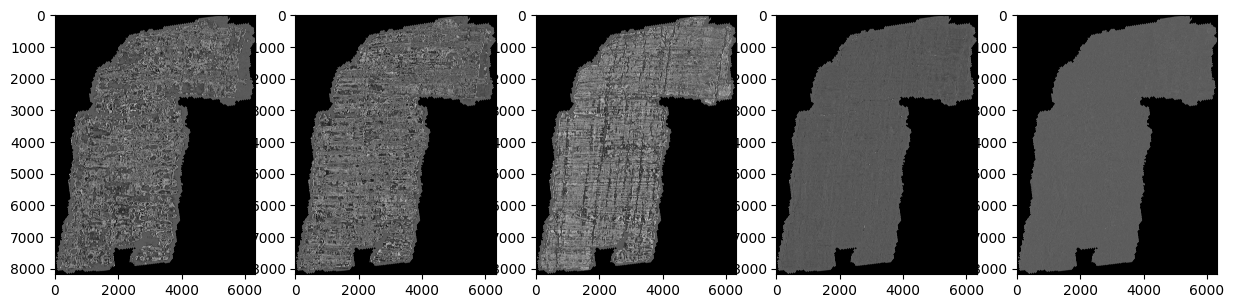

In [4]:
fig, axes = plt.subplots(1, 5, figsize = (15, 90))
axes[0].imshow(PIL.Image.open(f"{root}/Frag1/surface_volume/00.tif"), cmap='gray')
axes[1].imshow(PIL.Image.open(f"{root}/Frag1/surface_volume/15.tif"), cmap='gray')
axes[2].imshow(PIL.Image.open(f"{root}/Frag1/surface_volume/30.tif"), cmap='gray')
axes[3].imshow(PIL.Image.open(f"{root}/Frag1/surface_volume/45.tif"), cmap='gray')
axes[4].imshow(PIL.Image.open(f"{root}/Frag1/surface_volume/64.tif"), cmap='gray')

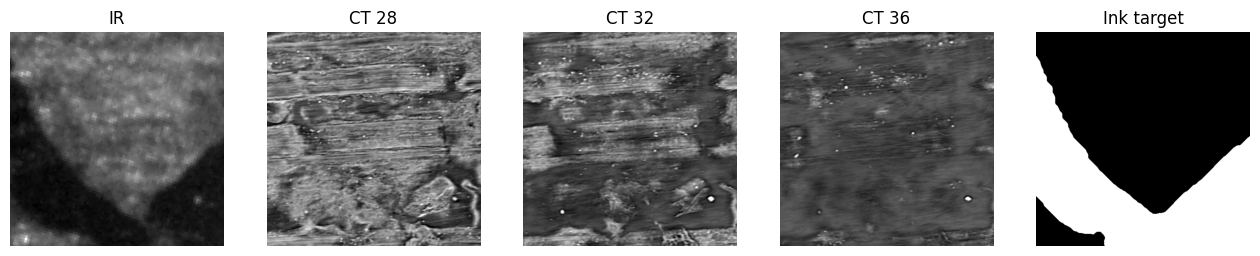

In [18]:
crop = numpy.s_[3793:4305, 2295:2807]
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
axes[0].imshow(ir[crop], cmap="gray")
axes[0].set_title("IR")
for ax, depth in zip(axes[1:4], [28, 32, 36]):
    with PIL.Image.open(root + "/Frag1" + f"/surface_volume/{depth:02d}.tif") as image:
        ax.imshow(numpy.array(image)[crop], cmap="gray")
    ax.set_title(f"CT {depth}")
axes[4].imshow(inklabels[crop] > 0, cmap="gray")
axes[4].set_title("Ink target")
for ax in axes:
    ax.axis("off")
plt.show()

In the example above, we are looking at a small fragment, and the ink is clearly recognizable here in both IR, and CT layer 32. However, CT 28 has only a fare-fetched barely visible silhouette, and CT 36 arguably has nothing. Thus, we need our algorithm to accurately find the exact layers where ink is visible. Otherwise, the prediction is impossible.

### Data exploration

In [36]:
import pandas

summary = []
for fragment in range(1, 7):
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png"))
    ink = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png"))
    assert mask.shape == ink.shape

    papyrus_pixels = numpy.count_nonzero(mask)
    ink_pixels = numpy.count_nonzero(mask & ink)
    summary.append({
        "fragment": fragment,
        "height": mask.shape[0],
        "width": mask.shape[1],
        "papyrus_pixels (mil.)": papyrus_pixels / 1e6,
        "ink_pixels (mil.)": ink_pixels / 1e6,
        "mask_coverage": papyrus_pixels / mask.size,
        "ink_fraction": ink_pixels / papyrus_pixels,
    })

summary = pandas.DataFrame(summary).set_index("fragment")
summary.round(3)

d:\Programs\Programming\Python\lib\site-packages\PIL\Image.py:3402: DecompressionBombWarning: Image size (140973980 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


,height,width,papyrus_pixels (mil.),ink_pixels (mil.),mask_coverage,ink_fraction
fragment,,,,,,
1,8181,6330,29.143,5.339,0.563,0.183
2,14830,9506,97.994,16.898,0.695,0.172
3,7606,5249,25.065,3.172,0.628,0.127
4,9791,6064,44.405,4.610,0.748,0.104
5,7309,4560,22.513,1.916,0.675,0.085
6,8853,6205,36.912,4.274,0.672,0.116


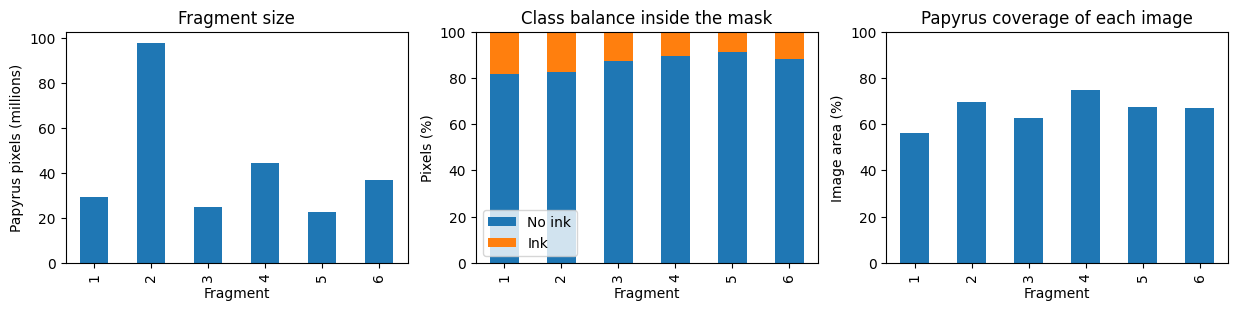

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3))

summary["papyrus_pixels (mil.)"].plot.bar(ax=axes[0])
axes[0].set(title="Fragment size", xlabel="Fragment", ylabel="Papyrus pixels (millions)")

balance = pd.DataFrame({"No ink": 1 - summary["ink_fraction"], "Ink": summary["ink_fraction"]})
balance.mul(100).plot.bar(stacked=True, ax=axes[1])
axes[1].set(title="Class balance inside the mask", xlabel="Fragment", ylabel="Pixels (%)", ylim=(0, 100))

summary["mask_coverage"].mul(100).plot.bar(ax=axes[2])
axes[2].set(title="Papyrus coverage of each image", xlabel="Fragment", ylabel="Image area (%)", ylim=(0, 100))
plt.show()

A few observations from these results:
- Fragment 2 is much bigger than the rest, almost reaching 100 million pixels
- Every fragment has around 60-70% of pixels covered by the papyrus. Thus, accounting for the mask should be important not only to improving the accuracy, but also to the performance of the models: a significant fraction of pixels do not contain ink a priori.
- Expectedly, there are much less ink pixels than no-ink pixels. Thus, we will have a huge class imbalance to deal with, just like in most segmentation problems

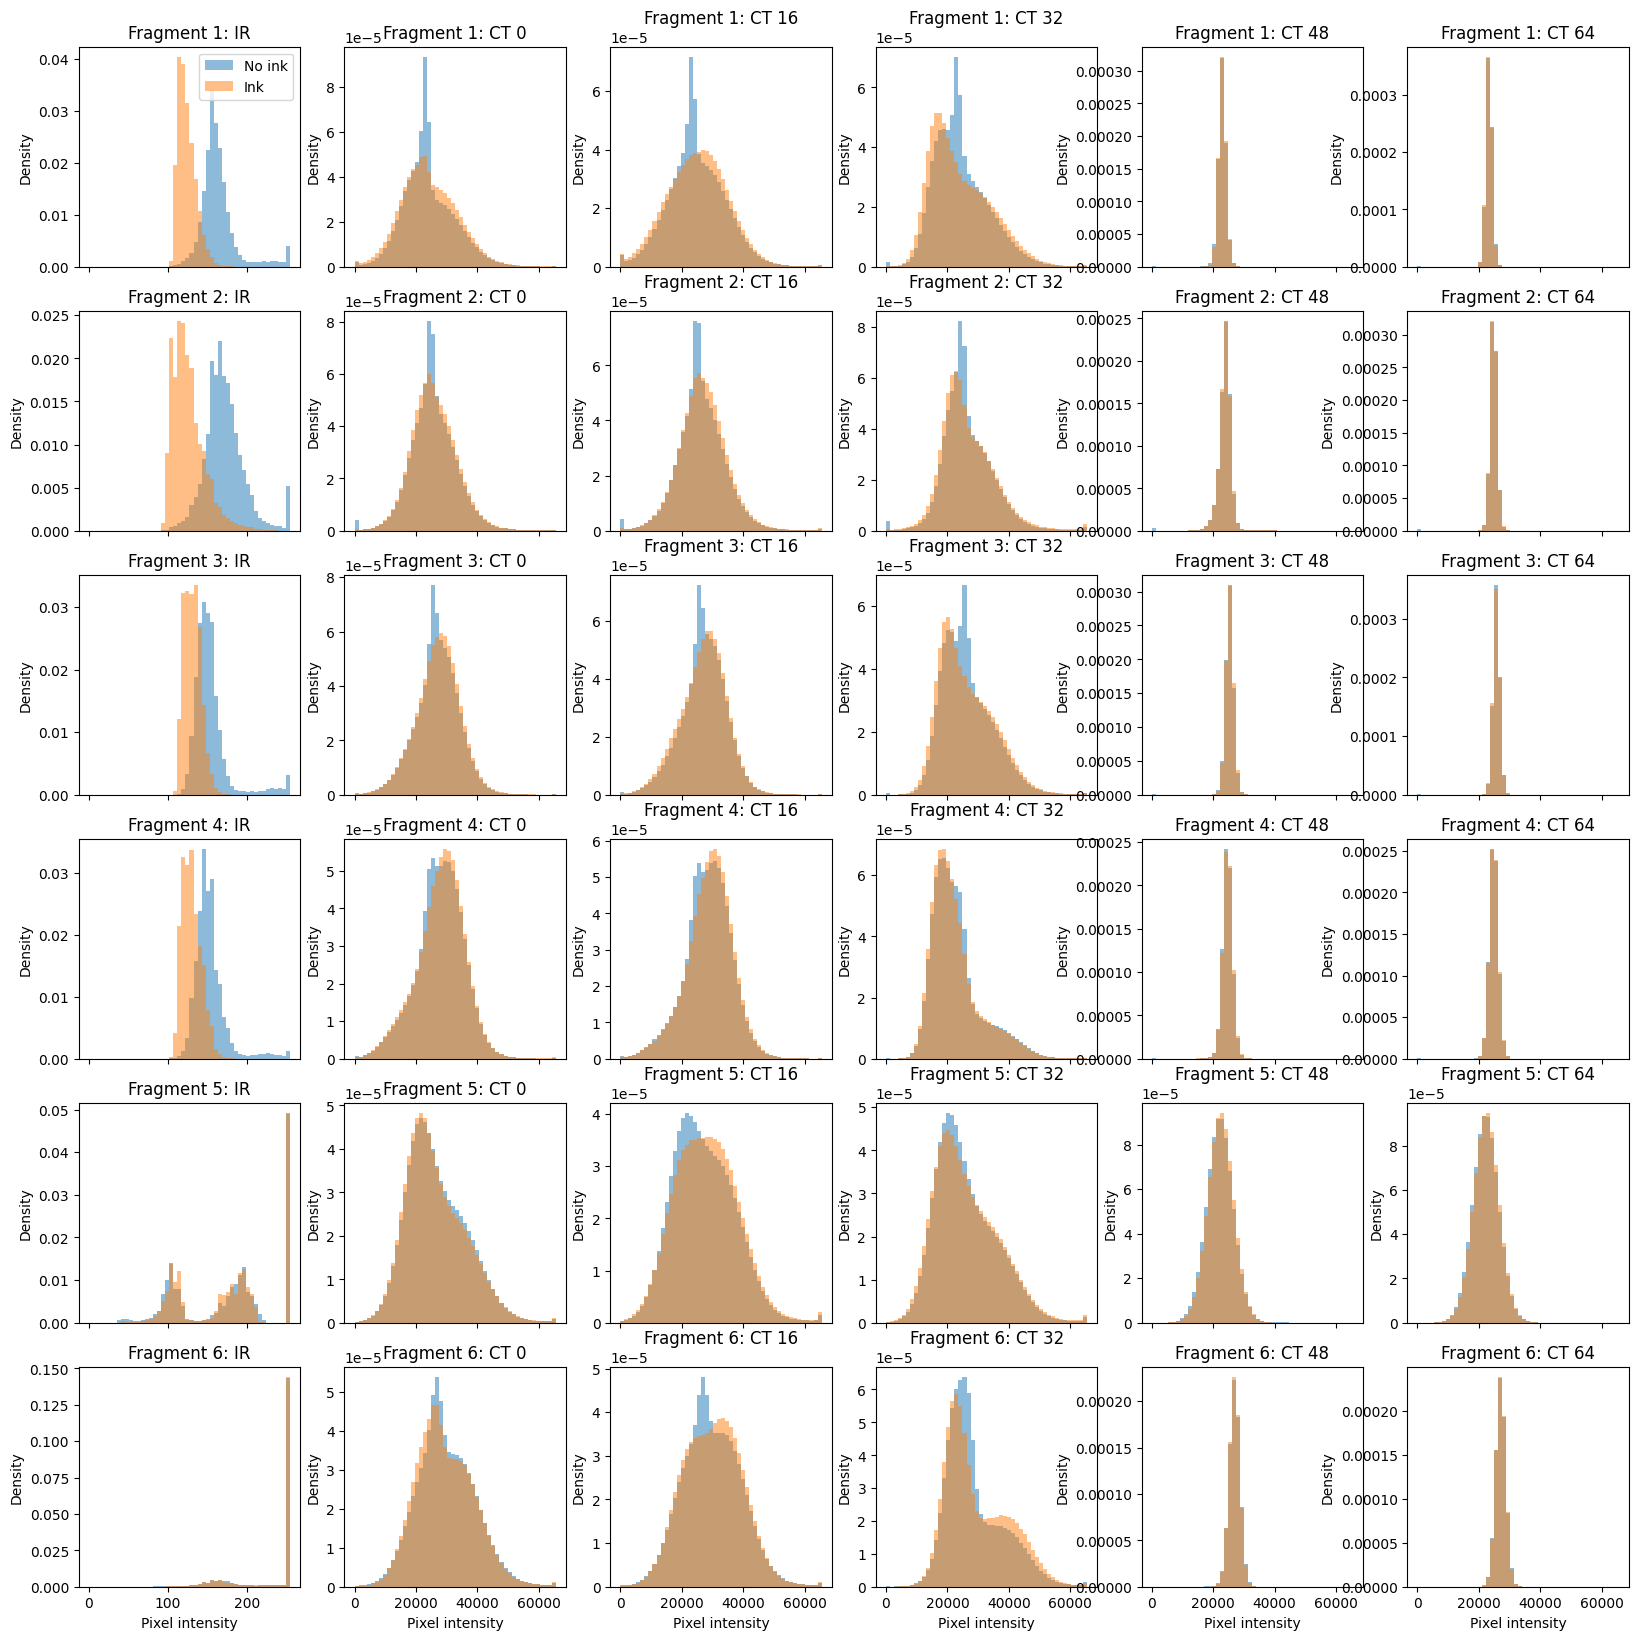

In [48]:
fig, axes = plt.subplots(6, 6, figsize=(20, 20), sharex="col")
for fragment in range(1, 7):
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png")) > 0
    pixels = numpy.flatnonzero(mask)
    ink = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png")).ravel()[pixels] > 0

    files = [("IR", "ir.png", 255)] + [(f"CT {depth}", f"surface_volume/{depth:02d}.tif", 65535) for depth in [0, 16, 32, 48, 64]]
    for column, (modality, filename, maximum) in enumerate(files):
        values = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/{filename}")).ravel()[pixels]
        for is_ink, label in [(False, "No ink"), (True, "Ink")]:
            axes[fragment - 1, column].hist(
                values[ink == is_ink],
                bins=numpy.linspace(0, maximum, 51),
                density=True,
                alpha=0.5,
                label=label
            )
        axes[fragment - 1, column].set(title=f"Fragment {fragment}: {modality}", ylabel="Density")
axes[0, 0].legend()
for ax in axes[-1]:
    ax.set_xlabel("Pixel intensity")
plt.show()